# 02 - Feature diagnostics (train files only)

**Scope:** only the 6 `Pre_train_*` files, loaded via the `train` list in `splits/splits.json`.
`Pre_submit_*` and `Fin_*` are held out, so their feature distributions must never shape design choices.
Features come from `data/features/` (`python -m src.features`), which are causal by construction (see `tests/test_features.py`).

**Goal:** check that each feature carries signal for the attack it targets, before any model is trained.
No models here.

Sections: 1. Class ratios · 2. Sentinel shares · 3. Distributions · 4. Univariate ROC-AUC (pooled and per file) ·
5. Sampling proposal · 6. Takeaways

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd

from src.features import BEHAVIORAL, FEATURES_DIR, ID_INCLUSIVE
from src.load import BYTE_COLS, CLASS_CATS, SUBCLASS_CATS, SUBSET_CATS
from src.train_stats import load_splits

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)

# Same fixed entity colors as 01_eda (never re-assigned by rank).
SUBCLASS_COLORS = {"Normal": "#2a78d6", "Flooding": "#eb6834", "Spoofing": "#1baf7a",
                   "Replay": "#eda100", "Fuzzing": "#e87ba4"}
ATTACKS = ["Flooding", "Spoofing", "Replay", "Fuzzing"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
# Sequential blue ramp (steps 100..700) for magnitude: light = no signal, dark = strong signal.
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
ID_ONLY = [f for f in ID_INCLUSIVE if f not in BEHAVIORAL]
FEATS = ID_INCLUSIVE  # behavioral first, then the ID-only extras

In [2]:
splits = load_splits()
TRAIN_FILES = splits["train"]
HELD_OUT = set(splits["test"]) | set(splits["extra_test"])
assert not HELD_OUT & set(TRAIN_FILES), "train list overlaps held-out files"

FIXED_CATS = {"source_file": TRAIN_FILES, "subset": SUBSET_CATS, "class": CLASS_CATS, "subclass": SUBCLASS_CATS}

def read_features(stem):
    d = pd.read_parquet(FEATURES_DIR / f"{stem}.parquet")
    for col, cats in FIXED_CATS.items():  # fixed categories -> concat stays categorical (low RAM)
        d[col] = pd.Categorical(d[col].astype(str), categories=cats)
    return d

df = pd.concat([read_features(f) for f in TRAIN_FILES], ignore_index=True)
loaded = set(df["source_file"].unique())
assert loaded == set(TRAIN_FILES) and not loaded & HELD_OUT, "only train files may be loaded here"
assert set(df["subset"].unique()) == {"prelim_train"}, "only prelim_train rows may be loaded here"
print(f"{len(df):,} frames from {len(loaded)} files; {len(FEATS)} features "
      f"({len(BEHAVIORAL)} behavioral + {len(ID_ONLY)} ID-only: {ID_ONLY})")
print(f"memory: {df.memory_usage(deep=True).sum() / 2**20:.0f} MB")

3,672,151 frames from 6 files; 24 features (22 behavioral + 2 ID-only: ['arb_id', 'id_seen_in_training'])
memory: 231 MB


## 1. Class ratios per file
Why: imbalance per file decides how to subsample for training (section 5), and the LODO folds need
every SubClass present in every validation fold.

In [3]:
counts = pd.crosstab(df["source_file"], df["subclass"]).reindex(columns=SUBCLASS_CATS)
pct = 100 * counts.div(counts.sum(axis=1), axis=0)
ratios = counts.assign(total=counts.sum(axis=1), **{"attack %": (100 - pct["Normal"]).round(2)})
ratios = ratios.join(pct[ATTACKS].round(2).add_suffix(" %"))
display(ratios)

lodo = splits["cv_schemes"][splits["cv_default"]]
fold_val = pd.DataFrame({fold["name"]: counts.loc[fold["val"], ATTACKS].sum() for fold in lodo}).T
fold_val.index.name = "LODO val fold: attack frames"
fold_val

subclass,Normal,Flooding,Spoofing,Replay,Fuzzing,total,attack %,Flooding %,Spoofing %,Replay %,Fuzzing %
source_file,,,,,,,,,,,
Pre_train_D_0,179346,0,0,0,0,179346,0.00,0.00,0.00,0.00,0.00
Pre_train_D_1,733752,38521,988,10509,22620,806390,9.01,4.78,0.12,1.30,2.81
Pre_train_D_2,811532,38852,2891,13266,22854,889395,8.75,4.37,0.33,1.49,2.57
Pre_train_S_0,180686,0,0,0,0,180686,0.00,0.00,0.00,0.00,0.00
Pre_train_S_1,727749,38151,988,10525,21879,799292,8.95,4.77,0.12,1.32,2.74
Pre_train_S_2,739678,38656,2889,13293,22526,817042,9.47,4.73,0.35,1.63,2.76


subclass,Flooding,Spoofing,Replay,Fuzzing
LODO val fold: attack frames,,,,
lodo_day1,76672,1976,21034,44499
lodo_day2,77508,5780,26559,45380


## 2. Sentinel shares (% of frames with value -1)
Why: -1 marks "no history yet" (first frame of an ID / of the stream, payload never seen) or "byte absent"
(DLC < 8). A model sees sentinels as real values, so we need to know how often they appear per SubClass
and whether that share is itself a label shortcut.

In [4]:
SENTINEL_FEATURES = ["dt_same_id", "dt_ratio", "dt_prev_frame", "payload_changed", "n_bytes_changed",
                     "payload_repeat_age"] + BYTE_COLS
sentinel_pct = (100 * (df[SENTINEL_FEATURES] == -1).groupby(df["subclass"], observed=True).mean()).T
display(sentinel_pct.round(3))

BINARY = ["is_first_of_id", "payload_changed", "payload_seen_before", "id_seen_in_training"]
rate_1 = (100 * (df[BINARY] == 1).groupby(df["subclass"], observed=True).mean()).T
rate_1.index.name = "% of frames with value 1"
rate_1.round(2)

subclass,Normal,Flooding,Spoofing,Replay,Fuzzing
dt_same_id,0.013,0.003,0.000,0.000,0.03
dt_ratio,0.013,0.003,0.000,0.000,0.03
dt_prev_frame,0.000,0.000,0.000,0.000,0.00
payload_changed,0.013,0.003,0.000,0.000,0.03
n_bytes_changed,0.013,0.003,0.000,0.000,0.03
payload_repeat_age,26.728,0.005,0.206,36.804,100.00
byte_0,0.000,0.000,0.000,0.000,0.00
byte_1,0.000,0.000,0.000,0.000,0.00
byte_2,0.166,0.000,0.000,0.168,0.00
byte_3,0.166,0.000,0.000,0.168,0.00


subclass,Normal,Flooding,Spoofing,Replay,Fuzzing
% of frames with value 1,,,,,
is_first_of_id,0.01,0.00,0.00,0.0,0.03
payload_changed,79.78,0.00,55.11,89.9,99.97
payload_seen_before,73.27,99.99,99.79,63.2,0.00
id_seen_in_training,99.99,0.00,100.00,100.0,92.30


## 3. Distributions (ECDF per SubClass)
Why: shows *where* each attack differs from Normal (shift, tail or spike), which AUC alone cannot.
Time features use a log x-axis. Sentinels (-1) are excluded here (their shares are in section 2).
For speed each SubClass is randomly subsampled to at most 200k frames (plotting only; AUCs use all frames).

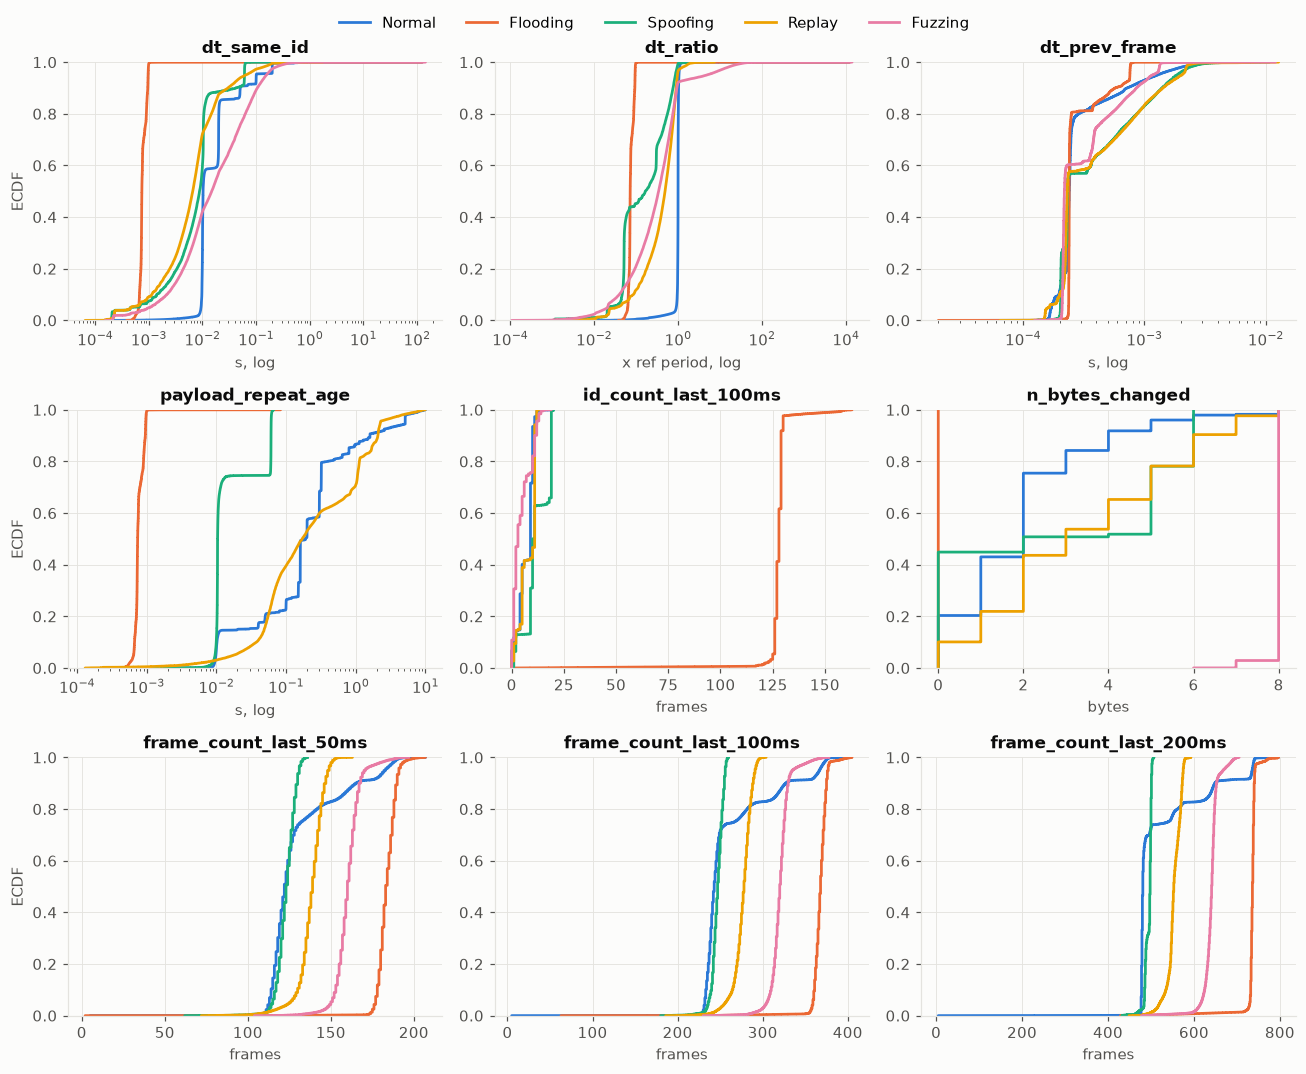

In [5]:
rng = np.random.default_rng(0)
MAX_PER_CLASS = 200_000
idx = [ix if len(ix) <= MAX_PER_CLASS else rng.choice(ix, MAX_PER_CLASS, replace=False)
       for ix in df.groupby("subclass", observed=True).indices.values()]
sample = df.iloc[np.sort(np.concatenate(idx))]

PLOT_FEATURES = [("dt_same_id", True, "s"), ("dt_ratio", True, "x ref period"), ("dt_prev_frame", True, "s"),
                 ("payload_repeat_age", True, "s"), ("id_count_last_100ms", False, "frames"),
                 ("n_bytes_changed", False, "bytes"), ("frame_count_last_50ms", False, "frames"),
                 ("frame_count_last_100ms", False, "frames"), ("frame_count_last_200ms", False, "frames")]
fig, axes = plt.subplots(3, 3, figsize=(12, 9.6))
for k, (ax, (col, logx, unit)) in enumerate(zip(axes.flat, PLOT_FEATURES)):
    for sc in SUBCLASS_CATS:
        v = sample.loc[(sample["subclass"] == sc) & (sample[col] != -1), col].to_numpy()
        if logx:
            v = v[v > 0]
        if len(v):
            ax.ecdf(v, color=SUBCLASS_COLORS[sc], label=sc, lw=1.8)
    if logx:
        ax.set_xscale("log")
    ax.set_title(col)
    ax.set_xlabel(unit + (", log" if logx else ""))
    ax.set_ylabel("ECDF" if k % 3 == 0 else "")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.show()

## 4. Univariate ROC-AUC per feature x SubClass (Normal vs that SubClass)
Why: a quick, model-free ranking of which feature separates which attack. Rank-based (Mann-Whitney:
AUC = P(attack > normal) + 0.5 P(tie)), computed exactly with a sorted Normal array, no new dependency.
Sentinels are included as-is, because that is what a model sees.
Shown as **separability = max(AUC, 1 - AUC)** with the direction: `+` means attack frames have higher values.
Rows below the line are ID-only features (excluded from the behavioral headline set).

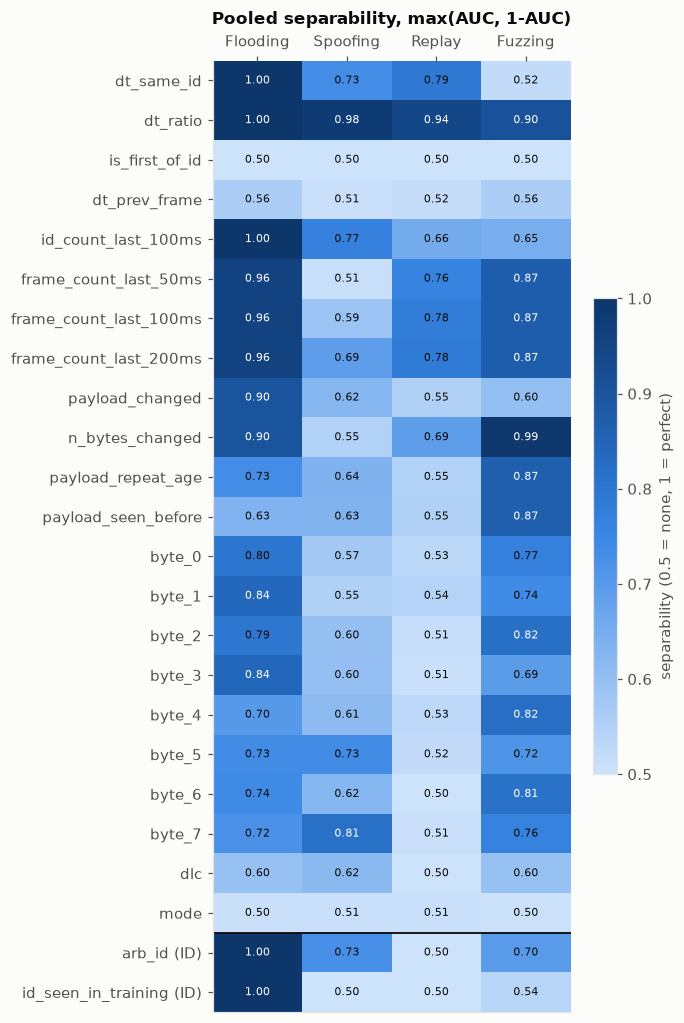

subclass,Flooding,Spoofing,Replay,Fuzzing
feature,,,,
dt_same_id,0.001 -,0.267 -,0.211 -,0.480 -
dt_ratio,0.003 -,0.020 -,0.057 -,0.095 -
is_first_of_id,0.500 -,0.500 -,0.500 -,0.500 +
dt_prev_frame,0.558 +,0.494 -,0.485 -,0.442 -
id_count_last_100ms,1.000 +,0.768 +,0.655 +,0.355 -
frame_count_last_50ms,0.956 +,0.509 +,0.760 +,0.872 +
frame_count_last_100ms,0.956 +,0.589 +,0.776 +,0.872 +
frame_count_last_200ms,0.956 +,0.691 +,0.783 +,0.871 +
payload_changed,0.101 -,0.377 -,0.551 +,0.601 +


In [6]:
def auc_vs_normal(neg_sorted, pos):
    # Mann-Whitney U / (n_pos * n_neg) with ties counted as 1/2.
    lo = np.searchsorted(neg_sorted, pos, side="left")
    hi = np.searchsorted(neg_sorted, pos, side="right")
    return float((lo + 0.5 * (hi - lo)).sum() / (len(pos) * len(neg_sorted)))

def auc_table(d):
    sub = d["subclass"].to_numpy()
    masks = {sc: sub == sc for sc in ["Normal"] + ATTACKS}
    rows = []
    for col in FEATS:
        x = d[col].to_numpy()
        neg = np.sort(x[masks["Normal"]])
        for sc in ATTACKS:
            if masks[sc].any():
                rows.append({"feature": col, "subclass": sc, "auc": auc_vs_normal(neg, x[masks[sc]])})
    return pd.DataFrame(rows)

def heatmap(ax, mat, title, show_ylabels=True):
    im = ax.imshow(mat.to_numpy(), cmap=SEQ_BLUE, vmin=0.5, vmax=1.0, aspect="auto")
    for (i, j), v in np.ndenumerate(mat.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.8 else INK)
    ax.set_xticks(range(mat.shape[1]), mat.columns)
    ax.set_yticks(range(mat.shape[0]), [f"{f} (ID)" if f in ID_ONLY else f for f in mat.index] if show_ylabels else [])
    ax.axhline(len(BEHAVIORAL) - 0.5, color=INK, lw=1.2)
    ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
    ax.grid(False)
    ax.set_title(title, pad=24)
    return im

auc = auc_table(df)
auc["separability"] = np.maximum(auc["auc"], 1 - auc["auc"])
auc["direction"] = np.where(auc["auc"] >= 0.5, "+", "-")
sep = auc.pivot(index="feature", columns="subclass", values="separability").reindex(index=FEATS, columns=ATTACKS)

fig, ax = plt.subplots(figsize=(6.2, 9.4))
im = heatmap(ax, sep, "Pooled separability, max(AUC, 1-AUC)")
fig.colorbar(im, ax=ax, shrink=0.5, label="separability (0.5 = none, 1 = perfect)")
plt.tight_layout(); plt.show()

auc_view = auc.assign(cell=auc["auc"].map("{:.3f}".format) + " " + auc["direction"])
auc_view.pivot(index="feature", columns="subclass", values="cell").reindex(index=FEATS, columns=ATTACKS)

### 4b. Stability across validation files
Why: a feature that separates well when pooled but poorly in one file will not generalise to the held-out
test files. Each attack file is scored on its own (its Normal vs its SubClass frames), using the **pooled
direction** (a model learns one direction, so a flip counts as a failure). Left: pooled. Right: the worst
of the 4 attack files (the LODO/LOFO validation files).

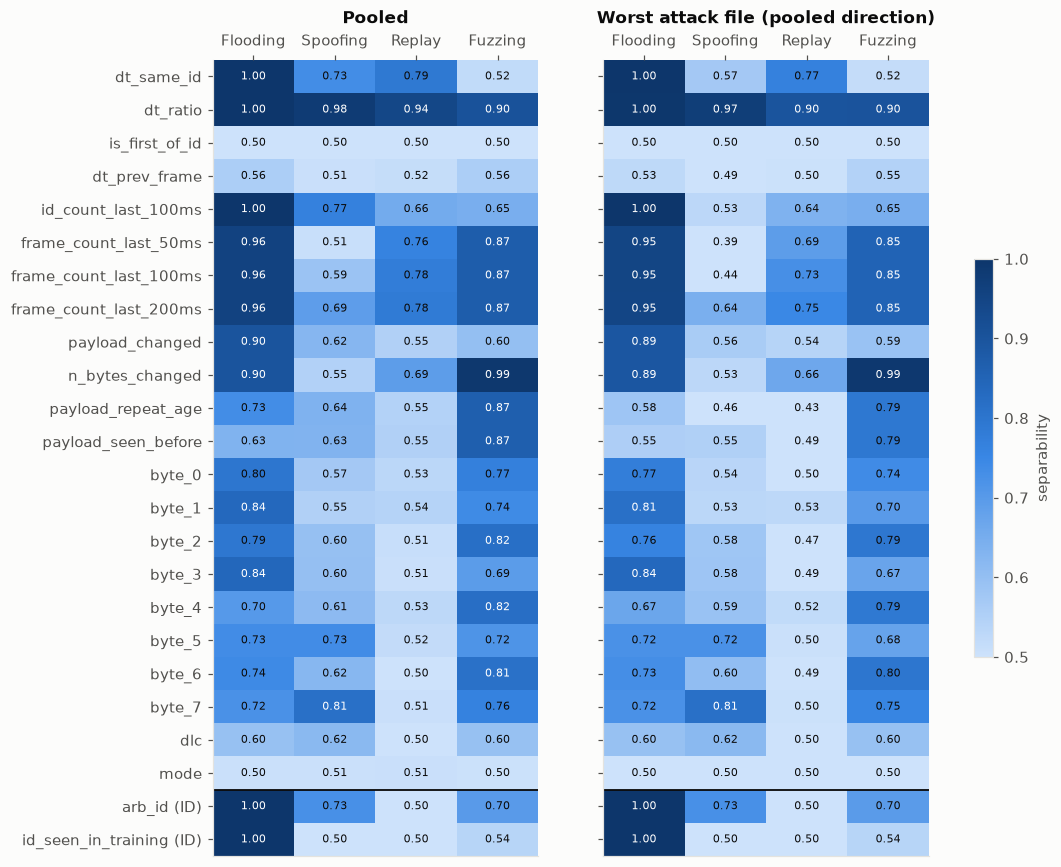

subclass,Flooding,Spoofing,Replay,Fuzzing
max - min across the 4 attack files,,,,
dt_same_id,0.000,0.217,0.031,0.005
dt_ratio,0.001,0.013,0.059,0.006
is_first_of_id,0.000,0.000,0.000,0.000
dt_prev_frame,0.066,0.028,0.021,0.026
id_count_last_100ms,0.000,0.315,0.024,0.002
frame_count_last_50ms,0.006,0.138,0.077,0.015
frame_count_last_100ms,0.007,0.164,0.046,0.015
frame_count_last_200ms,0.009,0.019,0.029,0.014
payload_changed,0.018,0.082,0.025,0.018


In [7]:
ATTACK_FILES = sorted({f for fold in lodo for f in fold["val"]})
by_file = pd.concat([auc_table(df[df["source_file"] == f]).assign(file=f) for f in ATTACK_FILES], ignore_index=True)
by_file = by_file.merge(auc[["feature", "subclass", "direction"]], on=["feature", "subclass"])
by_file["sep_pooled_dir"] = np.where(by_file["direction"] == "+", by_file["auc"], 1 - by_file["auc"])

g = by_file.groupby(["feature", "subclass"])["sep_pooled_dir"]
worst = g.min().unstack().reindex(index=FEATS, columns=ATTACKS)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 9.4))  # no sharey: hiding labels on one would hide both
heatmap(axes[0], sep, "Pooled")
im = heatmap(axes[1], worst, "Worst attack file (pooled direction)", show_ylabels=False)
fig.colorbar(im, ax=axes, shrink=0.5, label="separability")
plt.show()

spread = (g.max() - g.min()).unstack().reindex(index=FEATS, columns=ATTACKS)
spread.index.name = "max - min across the 4 attack files"
spread.round(3)

### 4c. Choosing `payload_history_max_age_s` (bounded payload history)
Why: with **unbounded** payload history the chance that a Normal payload was "seen before" grows with time since the
stream started, so `payload_seen_before` / `payload_repeat_age` partly encode *position in the file*, which CLAUDE.md
forbids as a feature. The feature files therefore use a bounded history: an entry older than M seconds counts as
never seen. M was chosen here on train data: the smallest M that flattens the seen-rate across file position
without hurting Replay.

The unbounded age is rebuilt from the stream (groupby on the payload key; the same definition as the extractor,
cross-checked in `tests/test_features.py`). A bound M then gives `age if age <= M else -1`, and the cell asserts that this
reproduces the stored 10 s features exactly. `timestamp` is used only to measure drift, never as a feature.

In [8]:
from src.features import BATCH_PAYLOAD_HISTORY_MAX_AGE_S as M_CHOSEN

age_unb = (df.groupby(["source_file", "arb_id", "dlc"] + BYTE_COLS, observed=True, sort=False)["timestamp"]
             .diff().fillna(-1).to_numpy())
capped = lambda m: age_unb if m is None else np.where(age_unb <= m, age_unb, -1.0)
assert np.array_equal(capped(M_CHOSEN).astype(np.float32), df["payload_repeat_age"].to_numpy()), \
    "bounded age derived from the stream must equal the stored features"

sub = df["subclass"].to_numpy()
rows = {}
for sc in ["Normal", "Replay", "Fuzzing"]:
    a = age_unb[sub == sc]; seen = a[a >= 0]
    rows[sc] = {"frames": len(a), "seen %": 100 * len(seen) / len(a),
                **{f"p{q} (s)": np.percentile(seen, q) if len(seen) else np.nan for q in (50, 90, 95, 99)},
                **{f"age <= {m} s %": 100 * (seen <= m).sum() / len(a) for m in (10, 30, 60)}}
display(pd.DataFrame(rows).T.round(2).rename_axis("unbounded payload_repeat_age"))

t_since_start = df["timestamp"] - df.groupby("source_file", observed=True)["timestamp"].transform("min")
BINS = [0, 10, 30, 60, 120, 200, 400]
bins = pd.cut(t_since_start, BINS, right=False)
is_norm = sub == "Normal"
drift_tables, comp = {}, []
for m in [None, 10, 30, 60]:
    a = capped(m); seen = (a >= 0).astype(np.int8)
    tab = 100 * pd.Series(seen[is_norm]).groupby(
        [df["source_file"].to_numpy()[is_norm], bins.to_numpy()[is_norm]], observed=True).mean().unstack()
    drift_tables[m] = tab
    post = tab[[c for c in tab.columns if m is None or c.left >= m]]
    r = {"max_age_s": "None" if m is None else m,
         "drift, all bins (pp, worst file)": (tab.max(axis=1) - tab.min(axis=1)).max(),
         "drift after first M s (pp, worst file)": (post.max(axis=1) - post.min(axis=1)).max()}
    for sc in ["Replay", "Fuzzing"]:
        for name, x in [("seen_before", seen), ("repeat_age", a)]:
            pooled = auc_vs_normal(np.sort(x[is_norm]), x[sub == sc])
            per = []
            for f in ATTACK_FILES:
                fm = (df["source_file"] == f).to_numpy()
                v = auc_vs_normal(np.sort(x[is_norm & fm]), x[fm & (sub == sc)])
                per.append(v if pooled >= 0.5 else 1 - v)
            r[f"{sc} {name}: pooled"] = max(pooled, 1 - pooled)
            r[f"{sc} {name}: worst file"] = min(per)
    comp.append(r)
display(pd.DataFrame(comp).set_index("max_age_s").T.round(3))

for m in [None, M_CHOSEN]:
    t = drift_tables[m].round(1)
    t.columns.name = f"Normal seen-rate % | s since file start | max_age={m}"
    display(t)

,frames,seen %,p50 (s),p90 (s),p95 (s),p99 (s),age <= 10 s %,age <= 30 s %,age <= 60 s %
unbounded payload_repeat_age,,,,,,,,,
Normal,3372743.0,79.76,0.20,5.13,24.95,109.76,73.27,76.22,77.92
Replay,47593.0,68.09,0.21,3.40,67.81,155.26,63.20,63.97,64.54
Fuzzing,89879.0,0.00,NaN,NaN,NaN,NaN,0.00,0.00,0.00


max_age_s,None,10,30,60
"drift, all bins (pp, worst file)",15.035,8.348,13.104,14.272
"drift after first M s (pp, worst file)",15.035,3.524,3.576,2.946
Replay seen_before: pooled,0.558,0.550,0.561,0.567
Replay seen_before: worst file,0.479,0.485,0.492,0.497
Replay repeat_age: pooled,0.556,0.546,0.564,0.573
Replay repeat_age: worst file,0.425,0.435,0.446,0.454
Fuzzing seen_before: pooled,0.899,0.866,0.881,0.890
Fuzzing seen_before: worst file,0.828,0.792,0.804,0.815
Fuzzing repeat_age: pooled,0.899,0.866,0.881,0.890
Fuzzing repeat_age: worst file,0.828,0.792,0.804,0.815


Normal seen-rate % | s since file start | max_age=None,"[0, 10)","[10, 30)","[30, 60)","[60, 120)","[120, 200)","[200, 400)"
Pre_train_D_0,53.1,59.7,62.8,64.1,NaN,NaN
Pre_train_D_1,59.4,59.5,65.2,64.9,66.0,67.3
Pre_train_D_2,64.6,59.2,64.1,66.3,66.7,70.1
Pre_train_S_0,82.4,91.8,94.7,95.0,NaN,NaN
Pre_train_S_1,82.8,94.1,97.1,96.3,96.9,96.8
Pre_train_S_2,80.6,88.2,91.4,92.3,95.7,93.9


Normal seen-rate % | s since file start | max_age=10.0,"[0, 10)","[10, 30)","[30, 60)","[60, 120)","[120, 200)","[200, 400)"
Pre_train_D_0,53.1,58.3,59.4,59.4,NaN,NaN
Pre_train_D_1,59.4,58.8,61.1,58.5,58.1,57.6
Pre_train_D_2,64.6,58.5,60.5,60.0,60.1,61.5
Pre_train_S_0,82.4,90.0,90.7,90.0,NaN,NaN
Pre_train_S_1,82.8,90.1,90.3,89.4,89.5,88.5
Pre_train_S_2,80.6,86.2,86.5,84.9,87.4,85.9


## 5. Sampling proposal (written, NOT applied)
Why: Normal is ~91% of every attack file and ~100% overall in the `_0` files. Subsampling decisions belong
here, before Colab training, but nothing is resampled in this phase.

Evidence for the anomaly-model rule below: Normal frames close in time to attack frames see inflated bus
counts (e.g. during floods), so they are not clean examples of normal behaviour. `timestamp` is used here
only to measure distance to attack frames (evaluation metadata), never as a feature.

In [9]:
MARGIN_S = 1.0
near_attack = np.zeros(len(df), dtype=bool)
ts_all, att_all = df["timestamp"].to_numpy(), df["is_attack"].to_numpy() == 1
for f, ix in df.groupby("source_file", observed=True).indices.items():
    t, att_t = ts_all[ix], np.sort(ts_all[ix][att_all[ix]])
    if not len(att_t):
        continue
    j = np.searchsorted(att_t, t)
    d_prev = np.where(j > 0, t - att_t[np.maximum(j - 1, 0)], np.inf)
    d_next = np.where(j < len(att_t), att_t[np.minimum(j, len(att_t) - 1)] - t, np.inf)
    near_attack[ix] = np.minimum(d_prev, d_next) <= MARGIN_S

normal = (df["subclass"] == "Normal").to_numpy()
rows = []
for f, ix in df.groupby("source_file", observed=True).indices.items():
    n_ix, near = ix[normal[ix]], near_attack[ix[normal[ix]]]
    fc = df["frame_count_last_100ms"].to_numpy()[n_ix]
    rows.append({"file": f, "normal_frames": len(n_ix), "within ±1 s of attack %": 100 * near.mean(),
                 "frame_count_100ms median (far)": np.median(fc[~near]),
                 "frame_count_100ms p95 (far)": np.percentile(fc[~near], 95),
                 "frame_count_100ms median (near)": np.median(fc[near]) if near.any() else np.nan,
                 "frame_count_100ms p95 (near)": np.percentile(fc[near], 95) if near.any() else np.nan})
pd.DataFrame(rows).set_index("file").round(1)

,normal_frames,within ±1 s of attack %,frame_count_100ms median (far),frame_count_100ms p95 (far),frame_count_100ms median (near),frame_count_100ms p95 (near)
file,,,,,,
Pre_train_D_0,179346,0.0,240.0,249.0,NaN,NaN
Pre_train_D_1,733752,44.7,240.0,247.0,278.0,371.0
Pre_train_D_2,811532,41.6,240.0,247.0,287.0,374.0
Pre_train_S_0,180686,0.0,239.0,249.0,NaN,NaN
Pre_train_S_1,727749,45.0,239.0,248.0,278.0,372.0
Pre_train_S_2,739678,45.0,240.0,247.0,284.0,373.0


In [10]:
# What a 4:1 Normal:Attack subsample per attack file would keep (illustration only, not applied).
RATIO = 4
plan = counts.assign(attack=counts[ATTACKS].sum(axis=1))
plan["normal_kept_4to1"] = np.where(plan["attack"] > 0, np.minimum(plan["Normal"], RATIO * plan["attack"]), plan["Normal"])
plan[["Normal", "attack", "normal_kept_4to1"] + ATTACKS]

subclass,Normal,attack,normal_kept_4to1,Flooding,Spoofing,Replay,Fuzzing
source_file,,,,,,,
Pre_train_D_0,179346,0,179346,0,0,0,0
Pre_train_D_1,733752,72638,290552,38521,988,10509,22620
Pre_train_D_2,811532,77863,311452,38852,2891,13266,22854
Pre_train_S_0,180686,0,180686,0,0,0,0
Pre_train_S_1,727749,71543,286172,38151,988,10525,21879
Pre_train_S_2,739678,77364,309456,38656,2889,13293,22526


**Proposal**

- **Supervised models:** keep every attack frame; subsample Normal per attack file to about 4:1 *after* features are
  computed (features need the full stream, so windows and payload history stay intact). Keep the `_0` files whole
  (they are small and Normal-only). Use class weights for the rare SubClass (Spoofing, ~7.8k frames).
  **Never resample validation or test**: metrics must reflect the real class ratio.
- **Anomaly models (train on Normal only):** Normal frames of `_0` plus Normal frames of the fold's training attack
  files that are *more than 1 s away from any attack frame*. Normal frames inside that margin have inflated bus counts
  (table above), so they would teach the model that attack-time traffic is normal.
- Sampling is done per CV fold from that fold's training files only.

## 6. Takeaways

**Class ratios.** Each attack file is 8.8-9.5% attack. Spoofing is rare: 988 frames per day-1 file and ~2.9k per
day-2 file, so the `lodo_day1` validation fold has only 1,976 Spoofing frames and Spoofing metrics will be noisy.

**Sentinels are not a shortcut**, with one intended exception. "First frame of an ID" is at most 0.03% in every
SubClass. `payload_repeat_age = -1` (payload not seen in the last 10 s) is 100% of Fuzzing vs 27% of Normal: random
payloads are never repeats, which is exactly the signal this feature was designed for.

**Behavioral features cover every attack type** (pooled separability; worst attack file in brackets):
| SubClass | best behavioral feature | runner-up |
|---|---|---|
| Flooding | `dt_same_id` / `dt_ratio` / `id_count_last_100ms` 1.00 (1.00) | `frame_count_*` 0.96 (0.95) |
| Spoofing | `dt_ratio` 0.98 (0.97) | `byte_7` 0.81 (0.81) |
| Replay | `dt_ratio` 0.94 (0.90) | `frame_count_last_200ms` 0.78 (0.75) |
| Fuzzing | `n_bytes_changed` 0.99 (0.99) | `dt_ratio` 0.90 (0.90), `payload_repeat_age` 0.87 (0.79) |

`dt_ratio` is the single strongest feature: normalising by the per-ID period turns raw `dt_same_id`
(Spoofing 0.73, Fuzzing 0.52) into 0.98 / 0.90. Weak on their own: `dt_prev_frame` (<= 0.56), `is_first_of_id` (0.50).
`mode` scores 0.50 everywhere, so it carries no label information by itself.

**ID-only features** make Flooding trivial (`arb_id`, `id_seen_in_training` = 1.00) and add little elsewhere
(`id_seen_in_training` 0.54 for Fuzzing). This confirms the ablation: behavioral-only stays the headline result.

**Window size (50 / 100 / 200 ms).** Identical for Flooding (0.96) and Fuzzing (0.87). For Spoofing only 200 ms helps
and is stable (0.69 pooled, 0.64 worst file); 50 and 100 ms *flip direction* in one file (worst 0.39 / 0.44). Replay
also prefers 200 ms (0.78 / 0.75). All three windows are already features; 200 ms looks like the better single
default (a decision for Phase 4).

**Payload history is bounded to 10 s (section 4c).** With unbounded history the Normal "seen before" rate climbed
with time since the stream started (S: ~81-83% -> 94-97%, D: ~53-65% -> 64-70%), an implicit position-in-file
feature. With M = 10 s the rate is flat after the first 10 s (worst-file range 3.5 pp vs 15.0 pp unbounded);
30 and 60 s flatten it equally after their longer warm-up, so 10 s is the smallest bound that works. Cost: Fuzzing
`payload_seen_before` drops 0.899 -> 0.866 (redundant: `n_bytes_changed` is 0.99).

**Payload history is weak for Replay** (~0.55 at every bound; the worst file flips direction). Replay's repeat ages
look like Normal's (median 0.21 vs 0.20 s, p90 3.4 vs 5.1 s), so "seen before" cannot separate them.
**`dt_ratio` (0.94) is what detects Replay**: replayed frames arrive on top of the real ones, shortening the per-ID gap.

The payload features still differ between files (spread 0.14-0.32), but now by **mode**, not position: the bounded
Normal seen-rate is ~86-90% in S files vs ~58-61% in D files, so e.g. Fuzzing scores ~0.95 in S files vs ~0.80 in D.
The model gets `mode`, so it can learn per-mode baselines.

**Sampling evidence.** Normal frames within +-1 s of an attack frame are 42-45% of Normal in each attack file, and
they are contaminated: `frame_count_last_100ms` median 278-287 vs 240 far from attacks (p95 ~372 vs ~248).
That supports excluding them from anomaly-model training. A 4:1 subsample keeps ~286k-311k Normal per attack file.